In [2]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [3]:
DATA_DIR = Path("../data/FIRE-SMOKE-DATASET/").resolve()

TRAIN_DIR = DATA_DIR / "Train"
TEST_DIR = DATA_DIR / "Test"

classes = ["Fire", "Smoke", "Neutral"]

print("Train exists:", TRAIN_DIR.exists())
print("Test exists:", TEST_DIR.exists())

FEATURE_DIR = DATA_DIR / "features"

data = np.load(
    FEATURE_DIR / "color_features.npz"
)

X_train = data["X_train"]
X_val = data["X_val"]
y_train = data["y_train"]
y_val = data["y_val"]

print(X_train.shape, X_val.shape)

Train exists: True
Test exists: True
(2160, 96) (540, 96)


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    )
)

svm_model.fit(X_train, y_train)

print("SVM training completed")

SVM training completed


Validation Accuracy: 0.7130
              precision    recall  f1-score   support

        Fire       0.82      0.68      0.75       180
       Smoke       0.70      0.76      0.73       180
     Neutral       0.65      0.70      0.67       180

    accuracy                           0.71       540
   macro avg       0.72      0.71      0.71       540
weighted avg       0.72      0.71      0.71       540



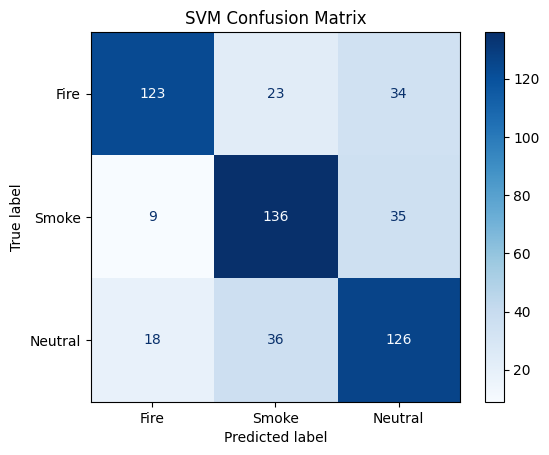

In [5]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

y_pred = svm_model.predict(X_val)

accuracy = accuracy_score(y_val, y_pred)

print(f"Validation Accuracy: {accuracy:.4f}")

print(
    classification_report(
        y_val,
        y_pred,
        target_names=classes
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    display_labels=classes,
    cmap="Blues"
)

plt.title("SVM Confusion Matrix")
plt.show()

Misclassified images: 155


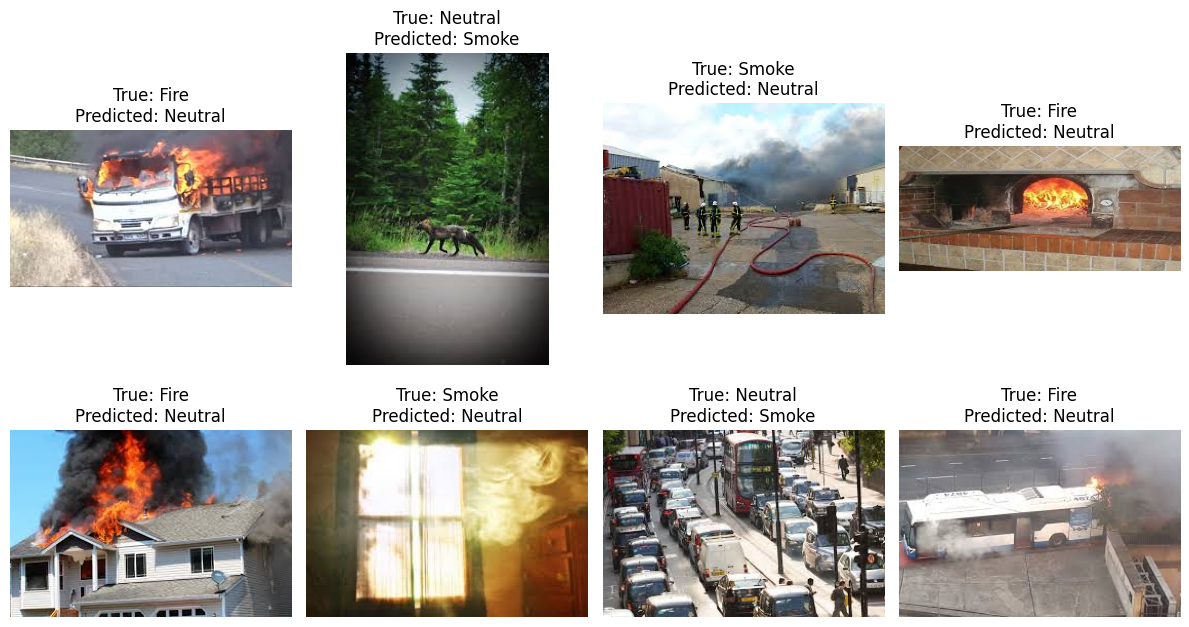

In [6]:
wrong_indices = np.where(y_pred != y_val)[0]

print("Misclassified images:", len(wrong_indices))

val_paths = data["val_paths"]

fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for ax, idx in zip(axes.flat, wrong_indices[:8]):
    img = cv2.imread(str(val_paths[idx]))

    if img is None:
        ax.axis("off")
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(
        f"True: {classes[y_val[idx]]}\n"
        f"Predicted: {classes[y_pred[idx]]}"
    )
    ax.axis("off")

for ax in axes.flat[len(wrong_indices[:8]):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# import joblib

# MODEL_DIR = DATA_ROOT / "models"
# MODEL_DIR.mkdir(parents=True, exist_ok=True)

# joblib.dump(
#     svm_model,
#     MODEL_DIR / "svm_rgb_hsv.joblib"
# )

# print("Model saved!")